# Experiment 22: ELoRA versus final-layer transfer — N = 100

Compare **22-ELoRA-N100-R4-9201369** with **19-LastLayerTransfer-N100-9189909**.
Both trained on the same 100 structures and are evaluated at their best validation
checkpoint on the same 50 validation structures: 2,400 Si and 4,800 O sites.
Targets are absolute DFT **isotropic shieldings in ppm**, not referenced chemical shifts.

## Results and interpretation

ELoRA reduces **Si RMSE from 1.984 to 1.393 ppm (29.8%)** and **O RMSE from
3.949 to 3.226 ppm (18.3%)**. MAE falls by 31.1% for Si and 29.4% for O.
The element-balanced standardised MSE decreases by **42.8%**. ELoRA improves this
loss on **49 of 50 structures**, supporting a widespread improvement rather than
one driven exclusively by a few structures.

ELoRA trains **29,060 parameters versus 141,380** (79.4% fewer). Both runs reached
early stopping, with best checkpoints at epochs **175 and 146**, respectively
(epochs are one-based throughout). The parity plots remain imperfect, especially
for low-shielding oxygen sites. This is evidence for better transfer in this
matched experiment; repeated seeds and held-out test evaluation remain outstanding.


## Load the verified predictions and check provenance

This notebook reuses the per-site predictions already computed from both best
checkpoints, checks source-file hashes, recomputes metrics and regenerates the plots
from those predictions. It does not just display saved PNGs. No test data are read.

To regenerate the predictions too, run from the project root:
```bash
.venv/bin/python experiments/22-ELoRA-vs-19-N100/analyse.py
```
The evaluator strictly loads `best.ckpt`, checks that `model.pt` matches it,
and verifies recomputed validation loss against the recorded best loss.


In [1]:
from pathlib import Path
import json, hashlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path(os.environ.get('NEQUIP_PROJECT', '/Users/louismcauliffe/code/research/NequIP_experiments'))
DATA = ROOT / 'experiments/22-ELoRA-vs-19-N100'
manifest = json.loads((DATA / 'manifest.json').read_text())
sites = pd.read_csv(DATA / 'validation-sites.csv.gz')
runs = pd.read_csv(DATA / 'runs.csv')
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
assert sha(ROOT / 'data/nmr_iso/valid.xyz') == manifest['validation_sha256']
assert sha(ROOT / 'data/nmr_iso/train.xyz') == manifest['train_file_sha256']
assert sha(ROOT / 'nmr_helpers/elora.py') == manifest['elora_implementation_sha256']
assert sha(ROOT / 'graph-pes-results/Kavanagh-Med-9059603/model.pt') == manifest['source_EF_sha256']
RUNS = {
    'Last layer + head': '19-LastLayerTransfer-LearningCurve/19-LastLayerTransfer-N100-9189909',
    'ELoRA rank 4 + head': '22-ELoRA-LearningCurve/22-ELoRA-N100-R4-9201369',
}
for method, folder in RUNS.items():
    run = runs.set_index('method').loc[method]
    directory = ROOT / 'graph-pes-results' / folder
    assert sha(directory / 'checkpoints/best.ckpt') == run.best_checkpoint_sha256
    assert sha(directory / 'model.pt') == run.model_sha256
    assert sha(directory / 'train-config.yaml') == run.config_sha256
    assert run.export_matches_best
    np.testing.assert_allclose(run.evaluated_balanced_mse, run.recorded_best_loss, rtol=5e-4)
labels = list(RUNS)
keys = ['structure', 'atom', 'element']
a, b = [sites[sites.method == method].sort_values(keys).reset_index(drop=True) for method in labels]
assert a[keys].equals(b[keys])
np.testing.assert_array_equal(a.reference_ppm, b.reference_ppm)
assert a.structure.nunique() == 50 and len(a) == 7200
assert a.element.value_counts().to_dict() == {'O': 4800, 'Si': 2400}
np.testing.assert_allclose(sites.prediction_ppm - sites.reference_ppm, sites.error_ppm, atol=1e-10)
print('Verified: identical 7,200 validation sites; checkpoint, model, config and data hashes match.')
display(runs[['method', 'best_epoch', 'final_epoch', 'checks_since_best',
              'trainable_parameters', 'recorded_best_loss', 'evaluated_balanced_mse']])


Verified: identical 7,200 validation sites; checkpoint, model, config and data hashes match.


,method,best_epoch,final_epoch,checks_since_best,trainable_parameters,recorded_best_loss,evaluated_balanced_mse
0,Last layer + head,146,446,300,141380,0.046630,0.046634
1,ELoRA rank 4 + head,175,475,300,29060,0.026683,0.026680


## Elemental accuracy at the selected checkpoint

The saved configurations have identical data, loss and fitting sections, seed 42,
and the same E/F starting checkpoint. The adaptation method changes: experiment 19
trains the fourth interaction layer and head; experiment 22 trains rank-4 adapters
across all four layers and the head. Both also train elemental scales and offsets.

Metrics below are pooled over atoms within each element. They describe the selected
best checkpoint, so they can differ from final-epoch W&B summary values.


In [2]:
rows = []
for (method, element), group in sites.groupby(['method', 'element'], sort=False):
    error = group.error_ppm.to_numpy()
    target = group.reference_ppm.to_numpy()
    rows.append(dict(method=method, element=element, sites=len(group),
        rmse_ppm=np.sqrt(np.mean(error**2)), mae_ppm=np.mean(abs(error)),
        bias_ppm=np.mean(error), r2=1-np.sum(error**2)/np.sum((target-target.mean())**2)))
metrics = pd.DataFrame(rows)
display(metrics.round(4))
comparison_rows = []
for element in ['Si', 'O']:
    for metric in ['rmse_ppm', 'mae_ppm']:
        values = metrics[metrics.element == element].set_index('method')[metric]
        comparison_rows.append({'Element': element, 'Metric': metric,
            'Last layer + head': values[labels[0]], 'ELoRA + head': values[labels[1]],
            'Reduction (%)': 100*(1-values[labels[1]]/values[labels[0]])})
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(3))


,method,element,sites,rmse_ppm,mae_ppm,bias_ppm,r2
0,Last layer + head,O,4800,3.9494,2.2326,-0.3458,0.9645
1,Last layer + head,Si,2400,1.9839,1.0299,-0.0494,0.9521
2,ELoRA rank 4 + head,O,4800,3.2261,1.5767,0.1266,0.9763
3,ELoRA rank 4 + head,Si,2400,1.3931,0.7101,0.0375,0.9764


,Element,Metric,Last layer + head,ELoRA + head,Reduction (%)
0,Si,rmse_ppm,1.984,1.393,29.781
1,Si,mae_ppm,1.030,0.710,31.056
2,O,rmse_ppm,3.949,3.226,18.313
3,O,mae_ppm,2.233,1.577,29.377


## Parity plots

Every site is included. Axes are identical between methods within each element;
the dashed diagonal is perfect prediction. The ELoRA point clouds are tighter for
both elements. Si improves more in relative RMSE; oxygen still has larger absolute
errors, with conspicuous outliers at low shielding. These plots alone do not identify
the coordination environments responsible for those outliers.


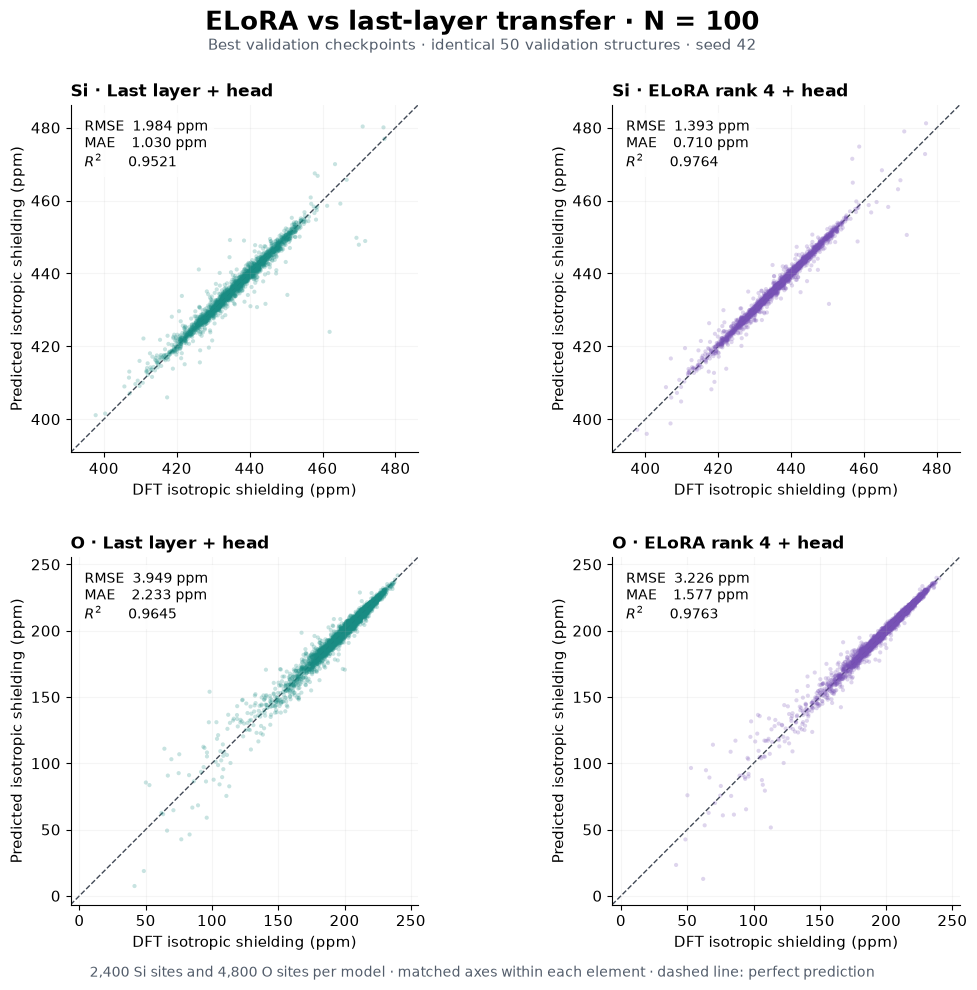

In [3]:
COLORS = ['#198C83', '#7751B5']
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'pdf.fonttype': 42, 'savefig.facecolor': 'white'})
labels = list(RUNS)
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for row, element in enumerate(['Si', 'O']):
    subset = sites[sites.element == element]
    low = min(subset.reference_ppm.min(), subset.prediction_ppm.min())
    high = max(subset.reference_ppm.max(), subset.prediction_ppm.max())
    margin = .06*(high-low)
    limits = [low-margin, high+margin]
    for col, method in enumerate(labels):
        ax = axes[row, col]
        data = subset[subset.method == method]
        m = metrics[(metrics.method == method) & (metrics.element == element)].iloc[0]
        ax.scatter(data.reference_ppm, data.prediction_ppm, s=9, alpha=.24,
            c=COLORS[col], edgecolors='none', rasterized=True)
        ax.plot(limits, limits, '--', c='#414956', lw=1, zorder=0)
        ax.set(xlim=limits, ylim=limits, aspect='equal',
            xlabel='DFT isotropic shielding (ppm)', ylabel='Predicted isotropic shielding (ppm)')
        ax.set_title(f'{element} · {method}', loc='left', weight='bold', fontsize=12)
        ax.text(.04, .96, f'RMSE  {m.rmse_ppm:.3f} ppm\nMAE    {m.mae_ppm:.3f} ppm\n$R^2$      {m.r2:.4f}',
            transform=ax.transAxes, va='top', fontsize=10,
            bbox=dict(facecolor='white', alpha=.9, edgecolor='none', pad=4))
        ax.grid(alpha=.12)
fig.suptitle('ELoRA vs last-layer transfer · N = 100', fontsize=19, weight='bold', y=.985)
fig.text(.5, .945, 'Best validation checkpoints · identical 50 validation structures · seed 42', ha='center', color='#535D6B')
fig.text(.5, .018, '2,400 Si sites and 4,800 O sites per model · matched axes within each element · dashed line: perfect prediction', ha='center', fontsize=10, color='#535D6B')
fig.subplots_adjust(top=.89, bottom=.09, left=.09, right=.97, hspace=.30, wspace=.27)
display(fig)
plt.close(fig)


## Does ELoRA improve most structures?

Use the same training objective, with fixed training-derived normalisers:

$$L_s=rac{1}{2}\left(rac{\mathrm{MSE}_{\mathrm{Si},s}}{8.789599019755547^2}
+rac{\mathrm{MSE}_{\mathrm{O},s}}{19.197689920683118^2}ight).$$

Each structure has 48 Si and 96 O atoms, so averaging these structure losses
reproduces the pooled balanced objective. In the paired plot, points below the
diagonal favour ELoRA. The largest-error structures remain difficult for both methods.


In [4]:
structure_rows = []
for (method, structure), group in sites.groupby(['method', 'structure']):
    mse = group.groupby('element').error_ppm.apply(lambda e: np.mean(e**2))
    structure_rows.append(dict(method=method, structure=structure,
        balanced_mse=.5*(mse['Si']/8.789599019755547**2 + mse['O']/19.197689920683118**2)))
structures = pd.DataFrame(structure_rows)
paired = structures.pivot(index='structure', columns='method', values='balanced_mse')
display(paired.agg(['mean', 'median']).round(6))
print(f'ELoRA lower on {(paired[labels[1]] < paired[labels[0]]).sum()}/50 structures.')
print(f'Mean balanced MSE reduction: {100*(1-paired[labels[1]].mean()/paired[labels[0]].mean()):.1f}%')
print('Five hardest structures for the baseline (zero-based indices in valid.xyz):')
display(paired.sort_values(labels[0], ascending=False).head().round(6))
print('Structure where ELoRA is worse:')
display(paired[paired[labels[1]] > paired[labels[0]]].round(6))


method,ELoRA rank 4 + head,Last layer + head
mean,0.026680,0.046634
median,0.004913,0.010106


ELoRA lower on 49/50 structures.
Mean balanced MSE reduction: 42.8%
Five hardest structures for the baseline (zero-based indices in valid.xyz):


method,ELoRA rank 4 + head,Last layer + head
structure,,
40,0.474701,0.797809
21,0.280968,0.402629
29,0.108872,0.176880
39,0.062571,0.158623
32,0.036994,0.071606


Structure where ELoRA is worse:


method,ELoRA rank 4 + head,Last layer + head
structure,,
11,0.016343,0.01366


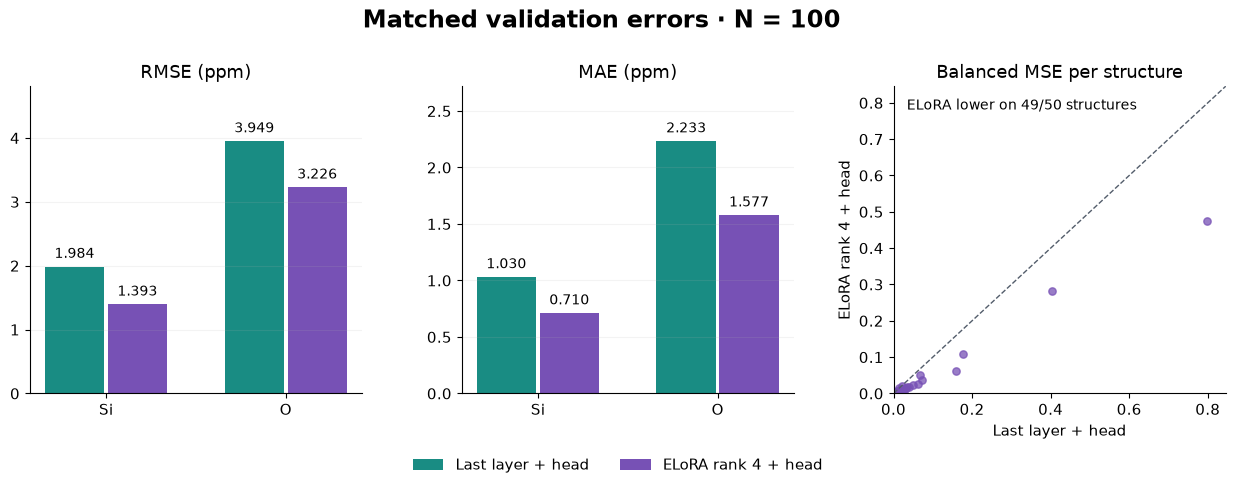

ELoRA has lower balanced loss on 49/50 validation structures.


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8))

for ax, metric, title in zip(axes[:2], ['rmse_ppm','mae_ppm'], ['RMSE (ppm)', 'MAE (ppm)']):
    for i, method in enumerate(labels):
        vals = [float(metrics[(metrics.method==method)&(metrics.element==e)][metric].iloc[0]) for e in ['Si','O']]
        bars = ax.bar(np.arange(2)+(i-.5)*.35, vals, width=.33, color=COLORS[i], label=method)
        ax.bar_label(bars, fmt='%.3f', padding=4, fontsize=10)
    ax.set_xticks([0,1], ['Si','O'])
    ax.set(title=title, ylim=(0, ax.get_ylim()[1]*1.16))
    ax.grid(axis='y', alpha=.15)
paired = structures.pivot(index='structure', columns='method', values='balanced_mse')
wins = int((paired[labels[1]] < paired[labels[0]]).sum())
max_loss = float(paired.to_numpy().max())*1.06
ax = axes[2]
ax.scatter(paired[labels[0]], paired[labels[1]], color=COLORS[1], s=28, alpha=.75)
ax.plot([0,max_loss], [0,max_loss], '--', color='#535D6B', lw=1)
ax.set(xlim=(0,max_loss), ylim=(0,max_loss), xlabel='Last layer + head', ylabel='ELoRA rank 4 + head', title='Balanced MSE per structure')
ax.text(.04,.96,f'ELoRA lower on {wins}/50 structures', transform=ax.transAxes, va='top', fontsize=10)
fig.suptitle('Matched validation errors · N = 100', fontsize=17, weight='bold', y=.99)
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles,legend_labels, loc='lower center', ncol=2, frameon=False)
fig.subplots_adjust(top=.83,bottom=.19,left=.06,right=.98,wspace=.30)
display(fig)
plt.close(fig)
print(f'ELoRA has lower balanced loss on {wins}/50 validation structures.', flush=True)


## Conclusion

This matched N=100 comparison supports ELoRA over final-layer transfer: both
elements improve, and 49/50 structures have lower balanced MSE. The median
per-structure loss drops from **0.010106 to 0.004913**, so the improvement extends
to typical structures as well as the high-error tail. Structure 11 is the sole
exception (zero-based validation-file indexing).

ELoRA uses **79.4% fewer trainable parameters**, but it is not faster in these
recorded runs: approximately **22.9 versus 14.6 minutes**. GPU hardware was not
controlled for this timing comparison. Both trained to the same stopping rule,
not an equal number of updates.

The result is a **single-seed validation comparison**, and validation selected the
checkpoints. It is not yet an independent test-set result or evidence of robustness
across seeds. Next, retain this recipe for the matched learning-curve comparison
and assess selected checkpoints on the held-out test split once choices are fixed.
